# Build an app: Week 1 workshop

Works through the steps of [Build an app with UvA AI Chat](cda-teaching-tools/workshops/week1/build-an-app.html). An image is an array of numbers, and this app shows that: you draw on a grid and see the grid as 0s and 1s.

**Who did what.** The exercise is meant for a group using UvA AI Chat, which needs a UvAnetID login. Here, Claude (in Claude Code) played the chatbot's role: it wrote the app and ran the tests. So the results below do not show what UvA AI Chat would build. The discussion questions for the group are still open and marked **To do**.

## 1. Write the specification

The course's specification, plus one addition of our own (the last line before "Keep the code short"):

```
Make me a small web app that I can try here in the chat.
- An 8 by 8 grid of squares, all white at the start.
- Clicking a square switches it between white and black.
- Below the grid, show the grid as a Python list of lists: 0 for white, 1 for black, one row per line. It changes with every click.
- A button "Count black pixels" that shows how many squares are black.
- A button "Clear" that makes all squares white again.
- A button "Invert" that swaps black and white.
Keep the code short and put a comment above each part, so that a beginner can read it.
```

**Invert** is a placeholder choice: replace it if your group wants a different addition.

## 2. Build it

The app is in [`pixel-grid.html`](pixel-grid.html), written in React. The next cell shows it here in the notebook. Try it: it needs an internet connection to load React.

**Changes asked for:** none. The first version passed every check in step 3.

In [1]:
import html
from IPython.display import display

with open('pixel-grid.html', encoding='utf-8') as f:
    app = f.read()

iframe = f'<iframe srcdoc="{html.escape(app, quote=True)}" width="100%" height="560" style="border:1px solid #bec6d1"></iframe>'
display({'text/html': iframe}, raw=True)

<iframe srcdoc="<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Pixel Grid</title>
<!-- React and Babel come from a CDN, so this file needs an internet connection -->
<script src="https://unpkg.com/react@18.3.1/umd/react.production.min.js"></script>
<script src="https://unpkg.com/react-dom@18.3.1/umd/react-dom.production.min.js"></script>
<script src="https://unpkg.com/@babel/standalone@7.26.4/babel.min.js"></script>
<style>
 body { font-family: system-ui, sans-serif; margin: 16px; color: #1f1d21; background: #fff; }
 .grid { display: inline-grid; grid-template-columns: repeat(8, 32px); gap: 2px; background: #bec6d1; border: 2px solid #bec6d1; }
 .square { width: 32px; height: 32px; padding: 0; border: 0; cursor: pointer; }
 .buttons { margin: 12px 0; display: flex; flex-wrap: wrap; gap: 8px; }
 .buttons button { font: inherit; padding: 4px 10px; cursor: pointer; }
 pre { font-size: 14px; margin: 8px 0; }
</style>
</head>
<body>
<div id="root"></div>

<script type="text/babel">
const SIZE = 8;

// Make a grid of 0s: a list of 8 rows, each a list of 8 numbers
function emptyGrid() {
 return Array.from({ length: SIZE }, () => Array(SIZE).fill(0));
}

function App() {
 // DATA STRUCTURE: the grid as a list of lists, kept with useState
 const [grid, setGrid] = React.useState(emptyGrid);
 // Has someone pressed "Count black pixels"?
 const [showCount, setShowCount] = React.useState(false);

 // EVENT: what a click on square (r, c) does: switch it between 0 and 1
 function toggle(r, c) {
 const next = grid.map(row => [...row]);
 // DECISION: if the square is black it becomes white, otherwise black
 if (next[r][c] === 1) {
 next[r][c] = 0;
 } else {
 next[r][c] = 1;
 }
 setGrid(next);
 }

 // Count the black squares again from the grid, so the count is never out of date
 const count = grid.flat().filter(value => value === 1).length;

 // Show the grid as a Python list of lists, one row per line
 const asPython =
 "[\n" + grid.map(row => " [" + row.join(", ") + "]").join(",\n") + "\n]";

 return (
 <div>
 {/* SEQUENTIAL: .map runs the same code for every row and every square: 64 squares */}
 <div className="grid">
 {grid.map((row, r) =>
 row.map((value, c) => (
 <button
 key={r + "-" + c}
 className="square"
 aria-label={"row " + r + ", column " + c}
 aria-pressed={value === 1}
 style={{ background: value === 1 ? "black" : "white" }}
 onClick={() => toggle(r, c)}
 />
 ))
 )}
 </div>

 <pre id="output">{asPython}</pre>

 {/* The buttons */}
 <div className="buttons">
 <button onClick={() => setShowCount(true)}>Count black pixels</button>
 <button onClick={() => setGrid(emptyGrid())}>Clear</button>
 {/* Our own addition in step 1: swap black and white */}
 <button onClick={() => setGrid(grid.map(row => row.map(value => 1 - value)))}>Invert</button>
 {/* The new feature of step 4: mirror each row from left to right */}
 <button onClick={() => setGrid(grid.map(row => [...row].reverse()))}>Mirror</button>
 </div>

 {showCount && <p id="count">Black pixels: {count}</p>}
 </div>
 );
}

ReactDOM.createRoot(document.getElementById("root")).render(<App />);
</script>
</body>
</html>
" width="100%" height="560" style="border:1px solid #bec6d1">

## 3. Test it, and read the code

**Test, do not trust.** These checks ran in a real browser, with scripted clicks on the squares and buttons of `pixel-grid.html`:

| Check | Result | |
|---|---|---|
| Click the top-left square. Does the first number of the first row become 1? | It became 1 | ✅ |
| Click it again. Does it go back to 0? | It went back to 0 | ✅ |
| Draw a 3. Does the count match yours? | Count is 15, and the list matches the 3 below | ✅ |
| Are there 8 rows of 8 numbers, top row first? | 8 rows of 8, top row `[0, 1, 1, 1, 1, 0, 0, 0]` | ✅ |
| Does **Clear** set all squares and the count to 0? | All 0, and "Black pixels: 0" | ✅ |
| Press **Count black pixels**, then click a square. Is the count still right? | 15 became 16, and 15 again after undoing | ✅ |

The 3 is taken from the example grid on the workshop page. Because an image is an array, NumPy can check the count by hand, and matplotlib can draw the same numbers as a picture:

Shape: (8, 8)
Black pixels: 15
Inverted, black pixels: 49


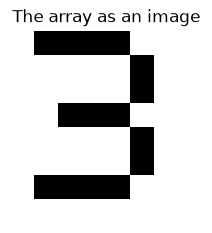

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# The 3 as copied from the app: 0 for white, 1 for black
three = np.array([
  [0, 1, 1, 1, 1, 0, 0, 0],
  [0, 0, 0, 0, 0, 1, 0, 0],
  [0, 0, 0, 0, 0, 1, 0, 0],
  [0, 0, 1, 1, 1, 0, 0, 0],
  [0, 0, 0, 0, 0, 1, 0, 0],
  [0, 0, 0, 0, 0, 1, 0, 0],
  [0, 1, 1, 1, 1, 0, 0, 0],
  [0, 0, 0, 0, 0, 0, 0, 0],
])

print('Shape:', three.shape)
print('Black pixels:', np.sum(three == 1))
print('Inverted, black pixels:', np.sum((1 - three) == 1))

plt.figure(figsize=(2.5, 2.5))
plt.imshow(three, cmap='Greys', vmin=0, vmax=1)
plt.title('The array as an image')
plt.axis('off')
plt.show()

### What did the chatbot decide that was not asked for?

- The count is worked out again from the grid every time, so it can never be out of date.
- The count stays hidden until the button is pressed. After that it stays visible, and **Clear** shows it as 0.
- The size of the squares (32 pixels), the grey lines between them and the wording "Black pixels: 15".
- The square brackets on their own lines around the printed list.
- Fixed versions of React and Babel, loaded from unpkg.

### The four patterns in the code

| Pattern | In `pixel-grid.html` |
|---|---|
| **Data structure** | `const [grid, setGrid] = React.useState(emptyGrid);` keeps the grid, a list of lists |
| **Sequential** | `grid.map((row, r) => row.map((value, c) => ( ... )))` makes the 64 squares |
| **Event driven** | `onClick={() => toggle(r, c)}` says what a click does |
| **A decision** | `if (next[r][c] === 1) { ... } else { ... }`, and `value === 1 ? "black" : "white"` for the colour |

## 4. Together

The class picks one new feature. **The mirror button** from the page's examples stands in here, and it is in the app as **Mirror**. In the browser test, the top row of the 3 became `[0, 0, 0, 1, 1, 1, 1, 0]`, and mirroring twice gave the original back. NumPy gives the same result:

Top row after mirroring: [0, 0, 0, 1, 1, 1, 1, 0]
Mirrored twice equals the original: True


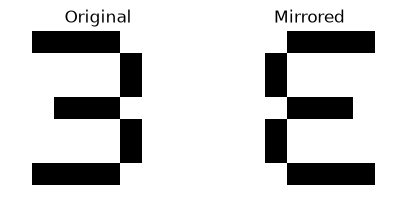

In [3]:
mirrored = np.fliplr(three)

print('Top row after mirroring:', mirrored[0].tolist())
print('Mirrored twice equals the original:', np.array_equal(np.fliplr(mirrored), three))

fig, axes = plt.subplots(1, 2, figsize=(5, 2.5))
for ax, image, title in zip(axes, [three, mirrored], ['Original', 'Mirrored']):
    ax.imshow(image, cmap='Greys', vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')
plt.show()

**To do (needs your group and class):**

- Did the same specification give different apps across groups?
- Which feature did your class actually pick? Did every group get the same thing?

## 5. Take the app out of the chat (optional)

- **Standalone file:** done. `pixel-grid.html` is one file with React and Babel loaded from a CDN. Double-click it to open it in a browser.
- **Works like the artifact:** this is the same file that was tested in step 3. There is no separate chat version to compare it with.
- **Online with GitHub Pages:** **not done**, because it changes your repository's settings and puts the page online. To do it, rename the file to `index.html`, upload it to a public repository, and choose your main branch under **Settings → Pages**.

**Why.** An app is made of this week's building blocks: a list, a loop, an event, an if. The chatbot writes them. You say what you want and check the result.